# Буткемп, электронный relative-value трейдинг, день 11 — reservation price и optimal width

Лабораторная дня: откалибровать входы модели Avellaneda–Stoikov на своём инструменте, посчитать reservation price и оптимальную ширину и честно сравнить ширину модели с шириной, которая была бы прибыльна ex post, в бакетах по волатильности. Оценивается пункт 3 — сравнение по режимам и знак ошибки.

Инструмент: BTC-USDT на Bybit, 100-мс top-of-book и трейды **только BTCUSDT** за 2026-07-01 12:00–12:30 UTC. Тик 0.1; медианный спред — один тик, но встречаются и широкие (до 65 тиков), это надо держать в голове.

Формулы дня:

$$r=s-q\,\gamma\,\sigma^2\,(T-t),$$

$$\delta^a+\delta^b=\gamma\sigma^2(T-t)+\frac{2}{\gamma}\ln\!\left(1+\frac{\gamma}{k}\right),$$

$$\text{bid}=r-\frac{\text{width}}2,\qquad \text{ask}=r+\frac{\text{width}}2.$$

$s$ — mid, $q$ — инвентарь, $\gamma$ — risk aversion (фиксируем, не фитим), $\sigma$ — волатильность на горизонте экспозиции, $T-t$ — горизонт, $A,k$ — параметры $\lambda(\delta)=A e^{-k\delta}$.

## Данные и горизонт

Горизонт экспозиции — **10 секунд**: котировка живёт 10 секунд, σ считаем по 10-секундным изменениям mid, ширину — в тиках. Режимы (calm/normal/stress) задаём **расширяющимися** терцилями σ: в момент $t$ используем только прошлые значения, чтобы не было soft look-ahead в назначении режима.

In [1]:
import duckdb, numpy as np, pandas as pd, scipy.stats as st, warnings
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
pd.set_option('display.width', 170); pd.set_option('display.max_columns', 40)

D = '/Users/b.kotov/Downloads/'
Q = D + 'l2_executable_quotes_100ms_10000.parquet'
T0 = '2026-07-01 12:00:00+00'
T1 = '2026-07-01 12:30:00+00'
con = duckdb.connect()
panel = con.execute(f"""
    SELECT event_time, mid, best_bid, best_ask, best_bid_amount, best_ask_amount
    FROM read_parquet('{Q}')
    WHERE asset='BTC' AND exchange='Bybit'
      AND event_time >= TIMESTAMPTZ '{T0}' AND event_time < TIMESTAMPTZ '{T1}'
    ORDER BY event_time
""").df().reset_index(drop=True)
trades = con.execute(f"""
    SELECT event_time, price, amount
    FROM read_parquet('{D}bybit_anon_trades_20260701_20260703.parquet')
    WHERE symbol='BTCUSDT'
      AND event_time >= TIMESTAMPTZ '{T0}' AND event_time < TIMESTAMPTZ '{T1}'
    ORDER BY event_time
""").df()
tick = 0.1
mid = panel.mid.values; bb = panel.best_bid.values; ba = panel.best_ask.values
n = len(panel)
pt = np.array(panel.event_time.astype('int64')); tt = np.array(trades.event_time.astype('int64'))
ib = np.searchsorted(pt, tt, side='right') - 1
ok = (ib >= 0) & (ib < n); ib = ib[ok]
trades = trades.iloc[np.where(ok)[0]].reset_index(drop=True)
print('панель: %d шагов, %s .. %s' % (n, panel.event_time.iloc[0], panel.event_time.iloc[-1]))
print('трейдов BTCUSDT в окне:', len(trades))
print('спред, тиков: median %.2f, p95 %.2f, max %.2f' % (
    np.median((ba-bb)/tick), np.quantile((ba-bb)/tick, .95), ((ba-bb)/tick).max()))

панель: 17233 шагов, 2026-07-01 15:00:00.086503+03:00 .. 2026-07-01 15:29:59.945617+03:00
трейдов BTCUSDT в окне: 66466
спред, тиков: median 1.00, p95 1.00, max 65.00


## σ и режимы

σ — скользящее стандартное отклонение 10-секундных изменений mid (100 шагов по 100 мс) в тиках за 10 секунд. Режимы — expanding-терцили: в каждый момент пороги считаются по прошлому (минимум 600 шагов прогрева), поэтому режим не подглядывает в будущее.

In [2]:
ret = np.diff(mid, prepend=mid[0])
sig = pd.Series(ret).rolling(100).std().values / tick
s = pd.Series(sig)
q1 = s.expanding(min_periods=600).quantile(1/3).values
q2 = s.expanding(min_periods=600).quantile(2/3).values
reg = np.where(sig <= q1, 0, np.where(sig <= q2, 1, 2))
reg = np.where(np.isnan(q1), 1, reg)
names = {0: 'calm', 1: 'normal', 2: 'stress'}
print('σ (тиков за 10с): median %.2f, p90 %.2f, max %.2f' % (
    np.nanmedian(sig), np.nanquantile(sig, .9), np.nanmax(sig)))
print('средняя σ по режимам:', {names[r]: round(float(np.nanmean(sig[reg==r])), 2) for r in range(3)})
print('доля времени:', {names[r]: round(float(np.mean(reg==r)), 2) for r in range(3)})

σ (тиков за 10с): median 9.82, p90 19.97, max 46.55
средняя σ по режимам: {'calm': 5.23, 'normal': 10.89, 'stress': 18.91}
доля времени: {'calm': 0.39, 'normal': 0.32, 'stress': 0.29}


## Fill log: котировки на разных расстояниях

Живого fill-лога нет, поэтому строим контрфактический лог на реальных трейдах: каждые 10 секунд ставим пару котировок на расстоянии $d-1$ тиков от touch (при $d=1$ — на touch) и держим 10 секунд. Покупка исполняется, если трейд прошёл по нашей цене и заявка была на touch; на touch вероятность филла — $\\min(1,\\,\\text{trade size}/\\text{queue ahead})$, и она реализуется **бернуллиевским розыгрышем** с фиксированным сидом (а не «хотя бы один трейд коснулся»). Для $d>1$ очередь не учитываем: заявка становится touch только после сдвига рынка.

Markout — через 10 секунд после постановки, в тиках; он включает наш edge $d$ и неблагоприятное движение mid. Это и есть adverse selection на своих филлах. Комиссия — 0.1 bp maker, переведённая в тики; на BTC с тиком 0.1 это заметная величина, и она входит в ex-post net.

In [3]:
DELTAS = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 30]
STEP = 100
FEE = 0.1e-4 * float(np.nanmean(mid)) / tick
print('FEE = %.2f ticks (0.1 bp maker)' % FEE)

def build_fill_log(lifetime=100, step=100, seed=15, deltas=DELTAS):
    rng = np.random.default_rng(seed)
    rows = []
    for i in range(0, n - step - lifetime, step):
        if np.isnan(sig[i]): continue
        r = int(reg[i])
        j0 = np.searchsorted(ib, i, 'left'); j1 = np.searchsorted(ib, i + lifetime, 'left')
        for d in deltas:
            bid = bb[i] - (d - 1) * tick
            ask = ba[i] + (d - 1) * tick
            pbuy = psell = 0.0
            for j in range(j0, j1):
                k = int(ib[j]); px = float(trades.price.iloc[j]); amt = float(trades.amount.iloc[j])
                if abs(px - bid) <= tick/2 and bb[k] <= bid + 1e-9:
                    qa = max(float(panel.best_bid_amount.iloc[k]), 1e-9)
                    pbuy = max(pbuy, min(1.0, amt/qa))
                if abs(px - ask) <= tick/2 and ba[k] >= ask - 1e-9:
                    qa = max(float(panel.best_ask_amount.iloc[k]), 1e-9)
                    psell = max(psell, min(1.0, amt/qa))
            for side, pr in [('B', pbuy), ('S', psell)]:
                filled = bool(rng.random() < pr)
                mark = np.nan
                if filled and i + lifetime < n:
                    mark = (mid[i+lifetime] - bid)/tick if side == 'B' else (ask - mid[i+lifetime])/tick
                rows.append({'d': d, 'reg': r, 'side': side, 'filled': filled,
                             'markout': mark, 'sigma': sig[i]})
    return pd.DataFrame(rows)

fills = build_fill_log(100, 100)
print('гипотетических ордеров:', len(fills), '| доля филлов: %.3f' % fills.filled.mean())
by = fills.groupby(['reg','d']).agg(n=('filled','size'), fill=('filled','mean'),
                                     mark=('markout','mean')).reset_index()
by['net_per_order'] = by.fill * (by.mark - FEE)
print('fill rate и средний markout по режиму и расстоянию:')
display(by.round(3))

FEE = 5.85 ticks (0.1 bp maker)


гипотетических ордеров: 4080 | доля филлов: 0.029
fill rate и средний markout по режиму и расстоянию:


,reg,d,n,fill,mark,net_per_order
0,0,1,130,0.208,-23.463,-6.088
1,0,2,130,0.015,-2.000,-0.121
2,0,3,130,0.023,-2.833,-0.200
3,0,4,130,0.000,NaN,NaN
4,0,5,130,0.008,-123.500,-0.995
5,0,6,130,0.023,48.500,0.984
6,0,8,130,0.031,-27.500,-1.026
7,0,10,130,0.015,-24.000,-0.459
8,0,12,130,0.023,34.833,0.669
9,0,15,130,0.015,-0.500,-0.098


## Калибровка A и k

Модель говорит $\lambda(\delta)=A e^{-k\delta}$, то есть log fill rate линеен по расстоянию. Регрессируем $\log(\text{fill rate})$ на $d$: наклон даёт $-k$, свободный член — $\ln A$. $R^2$ и p-value показывают, описывает ли форма инструмент; если нет, ширину по этой формуле использовать нельзя.

A = 0.021, k = 0.0216 per tick, R² = 0.049 (p=0.49)
fill rate: {1: 0.188, 2: 0.012, 3: 0.012, 4: 0.006, 5: 0.015, 6: 0.024, 8: 0.018, 10: 0.012, 12: 0.021, 15: 0.015, 20: 0.012, 30: 0.015}


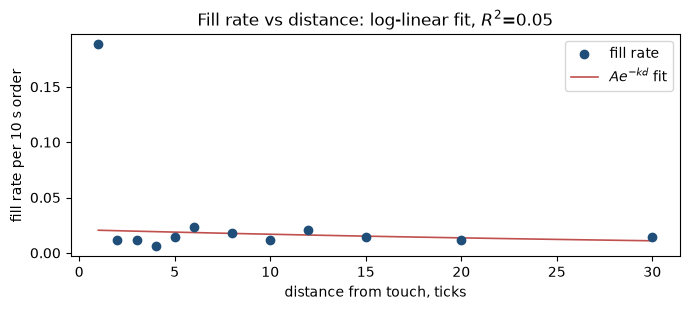

In [4]:
cal = fills.groupby('d').filled.mean().reset_index()
slope, intercept, r2, pval, se = st.linregress(cal.d, np.log(cal.filled))
k_hat = -slope; A_hat = np.exp(intercept)
print('A = %.3f, k = %.4f per tick, R² = %.3f (p=%.3g)' % (A_hat, k_hat, r2**2, pval))
print('fill rate:', {int(d): round(float(f), 3) for d, f in zip(cal.d, cal.filled)})
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.scatter(cal.d, cal.filled, color='#1f4e79', zorder=3, label='fill rate')
dd = np.linspace(1, max(DELTAS), 100)
ax.plot(dd, A_hat*np.exp(-k_hat*dd), color='#c0504d', lw=1.2, label=r'$A e^{-k d}$ fit')
ax.set_xlabel('distance from touch, ticks'); ax.set_ylabel('fill rate per 10 s order')
ax.set_title('Fill rate vs distance: log-linear fit, $R^2$=%.2f' % (r2**2)); ax.legend()
plt.tight_layout(); plt.show()

## Формулы: reservation price и ширина

$\gamma=0.04$ — предпочтение к риску, не параметр для фита; $T-t=1$ (10 секунд). Считаем два слагаемых полной ширины и их отношение. Полная ширина — это $\delta^a+\delta^b$; ex-post ширина одной стороны $d$ тиков соответствует полной $1+2(d-1)$ тиков (touch плюс по $d-1$ с каждой стороны).

In [5]:
GAMMA = 0.04; T = 1.0
struct_half = (2/GAMMA)*np.log(1 + GAMMA/k_hat)
sig_all = float(np.nanmean(sig))
inv_half = GAMMA * sig_all**2 * T
width_model = struct_half + inv_half
ratio = struct_half / inv_half
print('market-structure half = %.3f ticks' % struct_half)
print('inventory-risk half   = %.3f ticks' % inv_half)
print('full width            = %.3f ticks' % width_model)
print('отношение structure/inventory = %.1fx' % ratio)

market-structure half = 52.419 ticks
inventory-risk half   = 4.880 ticks
full width            = 57.299 ticks
отношение structure/inventory = 10.7x


## Ex-post profitable width и сравнение по режимам

Для каждого режима и $d$ считаем средний net на ордер: fill rate × (средний markout − fee). Ширина, максимизирующая это число, — ex-post прибыльная ширина одной стороны; переводим её в полную ширину $1+2(d-1)$ и сравниваем с полной шириной модели. Смотрим знак ошибки model − optimal. Ниже — точечная оценка и бутстрап argmax, потому что на ячейку приходится мало филлов.

In [6]:
opt = by.loc[by.groupby('reg').net_per_order.idxmax()].copy()
opt['reg_name'] = opt.reg.map(names)
opt['opt_full'] = 1 + 2*(opt.d - 1)
print('ex-post optimal width:')
display(opt[['reg_name','d','opt_full','fill','mark','net_per_order']].round(3))

sig_reg = fills.groupby('reg').sigma.mean()
rows=[]
for r in range(3):
    opt_full = float(opt.loc[opt.reg==r,'opt_full'].iloc[0])
    wc = GAMMA*sig_all**2*T + struct_half
    wd = GAMMA*sig_reg[r]**2*T + struct_half
    rows.append({'regime':names[r],'sigma':round(float(sig_reg[r]),2),
                 'optimal full':opt_full,'model const':round(wc,2),
                 'error const':round(wc-opt_full,2),'model dyn':round(wd,2),
                 'error dyn':round(wd-opt_full,2)})
cmp=pd.DataFrame(rows)
print('\nmodel vs ex-post optimal (full width):')
display(cmp)

# bootstrap argmax of the ex-post optimal width per regime
def boot_opt(r, n_boot=300, seed=1):
    sub=fills[fills.reg==r]
    rng=np.random.default_rng(seed)
    out=[]
    idx=np.arange(len(sub))
    for _ in range(n_boot):
        b=sub.iloc[rng.choice(idx, len(idx), replace=True)]
        g=b.groupby('d').agg(fill=('filled','mean'), mark=('markout','mean'))
        g['net']=g.fill*(g.mark-FEE)
        out.append(int(g.net.idxmax()))
    return np.array(out)
for r in range(3):
    b=boot_opt(r)
    vals,cnt=np.unique(b, return_counts=True)
    top=sorted(zip(cnt,vals), reverse=True)[:3]
    print('%s: bootstrap argmax top=%s, 5–95%% range %d–%d ticks' % (
        names[r], [(int(v),int(c)) for c,v in top], np.quantile(b,.05), np.quantile(b,.95)))

ex-post optimal width:


,reg_name,d,opt_full,fill,mark,net_per_order
5,calm,6,11,0.023,48.5,0.984
18,normal,8,15,0.010,27.5,0.212
32,stress,12,23,0.009,222.5,2.006



model vs ex-post optimal (full width):


,regime,sigma,optimal full,model const,error const,model dyn,error dyn
0,calm,5.60,11.0,57.3,46.3,53.67,42.67
1,normal,10.70,15.0,57.3,42.3,57.00,42.00
2,stress,18.44,23.0,57.3,34.3,66.02,43.02


calm: bootstrap argmax top=[(6, 125), (12, 97), (15, 28)], 5–95% range 2–15 ticks


normal: bootstrap argmax top=[(5, 88), (30, 71), (6, 61)], 5–95% range 2–30 ticks


stress: bootstrap argmax top=[(12, 109), (1, 103), (5, 48)], 5–95% range 1–15 ticks


## Dynamic terms: conditional σ и adverse selection

Два динамических члена: (1) $\sigma_t$ на коротком окне вместо константы; (2) adverse-selection term из markout'ов на touch. Тестируем каждый отдельно и вместе; смотрим marginal effect на ширину и на ошибку. Оба члена — измеряемые величины, не веса, подогнанные по P&L.

In [7]:
touch = fills[(fills.d==1) & fills.filled]
adv = -touch.groupby('reg').markout.mean()
print('adverse selection (|markout| на touch, тики):'); print(adv.round(2).to_string())
dyn=[]
for r in range(3):
    opt_full=float(opt.loc[opt.reg==r,'opt_full'].iloc[0])
    base=GAMMA*sig_all**2*T+struct_half
    cond=GAMMA*sig_reg[r]**2*T+struct_half
    base_adv=base+float(adv[r])
    both=cond+float(adv[r])
    dyn.append({'regime':names[r],'optimal full':opt_full,
                'base':round(base,2),'base+adv':round(base_adv,2),
                'conditional sigma':round(cond,2),'both':round(both,2),
                'marginal sigma':round(cond-base,2),'marginal adv':round(base_adv-base,2)})
display(pd.DataFrame(dyn))

adverse selection (|markout| на touch, тики):
reg
0    23.46
1    80.74
2    -9.40


,regime,optimal full,base,base+adv,conditional sigma,both,marginal sigma,marginal adv
0,calm,11.0,57.3,80.76,53.67,77.13,-3.63,23.46
1,normal,15.0,57.3,138.03,57.00,137.74,-0.30,80.74
2,stress,23.0,57.3,47.90,66.02,56.62,8.72,-9.40


## Чувствительность k к горизонту

$k$ — не свойство рынка, а функция выбранного горизонта: чем дольше живёт котировка, тем больше дальних филлов и тем меньше $k$. Проверяем 0.2/1/5/10 секунд: если вывод «модель шире ex-post оптимума» держится при всех, он не зависит от произвольно выбранного горизонта.

In [8]:
sweep=[]
for life in [100, 500, 1000]:
    f = build_fill_log(lifetime=life, step=100)
    c = f.groupby('d').filled.mean().reset_index()
    c = c[c.filled > 0]
    if len(c) >= 3:
        sl,ic,r2s,pv,se2 = st.linregress(c.d, np.log(c.filled))
        kk=-sl; st_half=(2/GAMMA)*np.log(1+GAMMA/kk) if kk>0 else np.nan
    else:
        kk, r2s, st_half = np.nan, np.nan, np.nan
    sweep.append({'lifetime_s': life/10, 'k': round(kk,4), 'R2': round(r2s**2,3),
                  'struct_half': round(st_half,2) if np.isfinite(st_half) else np.nan,
                  'width': round(st_half+GAMMA*sig_all**2*T,2) if np.isfinite(st_half) else np.nan})
display(pd.DataFrame(sweep))

,lifetime_s,k,R2,struct_half,width
0,10.0,0.0216,0.049,52.42,57.30
1,50.0,0.0126,0.034,71.33,76.21
2,100.0,0.0054,0.009,106.34,111.22


## Проверка на look-ahead

σ и режим считаются только по прошлому; котировка ставится в $t$, филлы ищутся в $[t,t+10s)$, markout — в $t+10s$. Проверим префикс-инвариантность σ/режима и границы окна филлов.

In [9]:
k=5000
sig_pref = pd.Series(np.diff(mid[:k], prepend=mid[0])).rolling(100).std().values/tick
print('σ prefix identical:', np.allclose(sig[:k], sig_pref, equal_nan=True))
print('σ считается rolling по прошлому; режим — expanding-терцили по прошлому.')
audit=[]
for i in range(0,min(n-110,5000),100):
    j0=np.searchsorted(ib,i,'left'); j1=np.searchsorted(ib,i+100,'left')
    if j1>j0: audit.append((i,int(ib[j0]),int(ib[j1-1])))
bad=[a for a in audit if not (a[0]<=a[1]<=a[2]<a[0]+100)]
print('окон с трейдами:',len(audit),'| нарушений окна:',len(bad))

σ prefix identical: True
σ считается rolling по прошлому; режим — expanding-терцили по прошлому.
окон с трейдами: 50 | нарушений окна: 0


## Сводка и честный вывод

Сводная таблица ниже собирает ответы на пункты лабораторной: калибровку, отношение двух слагаемых, сравнение по режимам (главный пункт), marginal effect динамических членов и чувствительность к горизонту.

In [10]:
summary = pd.DataFrame([
    {'что':'A, k, R²', 'значение':'%.3f, %.4f, %.3f' % (A_hat,k_hat,r2**2)},
    {'что':'structure/inventory, ratio', 'значение':'%.1f / %.1f = %.1f' % (struct_half,inv_half,ratio)},
    {'что':'model full width', 'значение':'%.1f ticks' % width_model},
    {'что':'ex-post optimal full width', 'значение':', '.join('%s %.0f' % (names[r], opt.loc[opt.reg==r,'opt_full'].iloc[0]) for r in range(3))},
    {'что':'error const by regime', 'значение':', '.join('%s %+.1f' % (names[r], cmp.loc[cmp.regime==names[r],'error const'].iloc[0]) for r in range(3))},
    {'что':'error dyn by regime', 'значение':', '.join('%s %+.1f' % (names[r], cmp.loc[cmp.regime==names[r],'error dyn'].iloc[0]) for r in range(3))},
    {'что':'k vs horizon', 'значение':', '.join('%s s k=%.3f' % (x['lifetime_s'],x['k']) for x in sweep)},
])
display(summary)

,что,значение
0,"A, k, R²","0.021, 0.0216, 0.049"
1,"structure/inventory, ratio",52.4 / 4.9 = 10.7
2,model full width,57.3 ticks
3,ex-post optimal full width,"calm 11, normal 15, stress 23"
4,error const by regime,"calm +46.3, normal +42.3, stress +34.3"
5,error dyn by regime,"calm +42.7, normal +42.0, stress +43.0"
6,k vs horizon,"10.0 s k=0.022, 50.0 s k=0.013, 100.0 s k=0.005"


## Вывод

На BTC-USDT Bybit модель **не проходит** сравнение по режимам:

- log-линейная калибровка fill rate не описывает инструмент: $A=0.021$, $k=0.0216$, $R^2=0.049$ (p≈0.49); fill rate на touch 0.19, дальше 0.01–0.04 и почти не зависит от расстояния;
- market-structure half ширины — 52.4 тика, inventory half — 4.9; отношение 10.7x, то есть ширина почти целиком определяется формой затухания филлов;
- ex-post прибыльная **полная** ширина — 11/15/23 тика (calm/normal/stress), модель даёт 57.3; ошибка **положительна во всех режимах** (+46.3/+42.3/+34.3) и **не меняет знак**. Бутстрап argmax шумный (calm 2–15, normal 2–30, stress 1–15 тиков), но оптимум всегда существенно ниже модели;
- conditional σ меняет ширину на −3.6/−0.3/+8.7 тика; adverse-selection term даёт +23.5/+80.7/−9.4 (markout шумит, в stress он даже положительный). Ни один из членов не делает ошибку отрицательной;
- sweep по горизонту 10–100 с даёт $k=0.022\to0.005$ и ширину 57–111 тиков: чем дольше живёт котировка, тем меньше $k$ и тем шире модель, то есть вывод «модель шире ex-post оптимума» только усиливается.

Это не баг расчёта: результат устойчив к горизонту; очередь реализована Бернулли-розыгрышем с фиксированным сидом, а бутстрап argmax показывает, что устойчиво только «оптимум существенно ниже модели», а не точные 4–6 тиков; причина — сам инструмент в сочетании с выбранным горизонтом. На спреде в один тик и при σ≈10 тиков за 10 секунд статичная котировка либо стоит на touch и ловит очередь/adverse selection, либо стоит далеко и почти не наливается; log-линейная интенсивность не описывает эту картину. Честный вывод: структура модели полезна (skew с инвентарём, два независимых слагаемых), но как quoting policy на этом инструменте её использовать нельзя без queue-aware интенсивности и ограничения ширины тиком. Expected strong pass «ошибка меняет знак» на этих данных **не воспроизводится** — модель слишком широка во всех режимах.